# ДЗ 3. Ускорение Python: Cython, Numba, ctypes, pybind11

Тема про то, что делать, когда чистый Python (даже с NumPy) оказывается недостаточно быстрым, а
переписывать всё на C++ целиком не хочется. Четыре инструмента, которые сегодня разберём, решают
одну и ту же задачу — вызвать скомпилированный код из Python — но очень по-разному:

- **Numba** — JIT-компиляция прямо из Python-функции (`@njit`), почти без изменений кода.
- **Cython** — Python-подобный язык, компилируется в C; чем больше типов вы укажете, тем быстрее.
- **ctypes** — вызов уже существующей скомпилированной C-библиотеки без каких-либо оберток.
- **pybind11** — написание полноценного C++ расширения с автоматической генерацией Python-биндингов.

Сквозные примеры: **множество Мандельброта** (красиво, embarrassingly parallel) и
**N-тел** — расчёт гравитационных сил между N частицами (классическая O(N²) задача, физически
осмысленная, с естественной проверкой правильности через третий закон Ньютона).

**Важно про среду выполнения.** В Google Colab доступен компилятор `g++`/`gcc` "из коробки", и
`pip install cython pybind11` работает без проблем. Если что-то из этого недоступно в вашей
среде — используйте Colab специально для этого ДЗ.

In [37]:
import numpy as np
import time
import matplotlib.pyplot as plt

## Уровень 1. Попроще

### Задача 1.1. Множество Мандельброта: Python vs NumPy vs Numba

Точка $c$ принадлежит множеству Мандельброта, если последовательность $z_{n+1} = z_n^2 + c$
(с $z_0=0$) не уходит на бесконечность. На практике: если $|z_n| > 2$, последовательность гарантированно
разойдётся — тогда запоминаем номер итерации `it`, на которой это произошло (чем меньше — тем
"дальше" точка от множества).

1. Реализуйте `mandelbrot_python(width, height, max_iter, ...)` — наивная версия с вложенными
   Python-циклами по пикселям.
2. Реализуйте `mandelbrot_numba` — **тот же самый код**, обёрнутый в `@njit`.
3. Реализуйте `mandelbrot_numpy` — векторизованная версия без явных циклов по пикселям (все точки
   обрабатываются одновременно на каждой итерации, с помощью булевой маски "ещё не разошедшихся"
   точек).
4. Сравните все три на **точное** совпадение результата (не приближённое!) и на скорость.
   Визуализируйте результат через `plt.imshow`.

**Подсказка/ловушка:** используйте `np.linspace` для сетки координат **одинаково** во всех трёх
версиях — на первый взгляд эквивалентные формулы сетки (`xmin + j*(xmax-xmin)/width` против
`np.linspace(xmin, xmax, width)`) на самом деле немного отличаются (разный шаг: делится на
`width` или на `width-1`), и результаты не совпадут "неожиданно" по причинам, не имеющим отношения
к Cython/Numba.

Python: 2.7941 сек
Numba: 0.1151 сек
NumPy: 0.4190 сек
Все три версии дали идентичный результат.


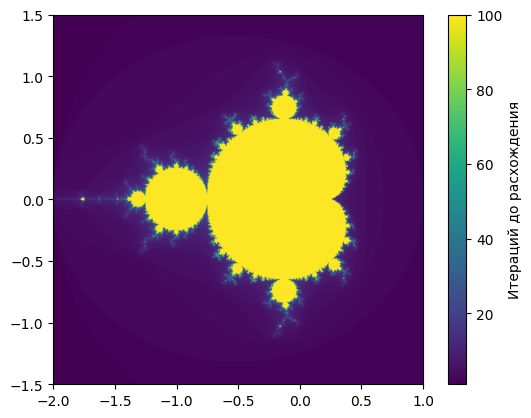

In [38]:
# TODO: mandelbrot_python, mandelbrot_numba, mandelbrot_numpy + сравнение и визуализация
import numpy as np
import numba as nb
import matplotlib.pyplot as plt
import time

width, height = 800, 600
max_iter = 100
xmin, xmax = -2.0, 1.0
ymin, ymax = -1.5, 1.5

x = np.linspace(xmin, xmax, width)
y = np.linspace(ymin, ymax, height)

def mandelbrot_python(width, height, max_iter, x, y):
    result = np.zeros((height, width), dtype=np.int32)
    for i in range(height):
        for j in range(width):
            c = complex(x[j], y[i])
            z = 0j
            for it in range(max_iter):
                if abs(z) > 2.0:
                    break
                z = z * z + c
            else:
                it = max_iter
            result[i, j] = it
    return result

@nb.njit
def mandelbrot_numba(width, height, max_iter, x, y):
    result = np.zeros((height, width), dtype=np.int32)
    for i in range(height):
        for j in range(width):
            c = complex(x[j], y[i])
            z = 0j
            for it in range(max_iter):
                if abs(z) > 2.0:
                    break
                z = z * z + c
            else:
                it = max_iter
            result[i, j] = it
    return result

def mandelbrot_numpy(width, height, max_iter, x, y):
    X, Y = np.meshgrid(x, y)
    C = X + 1j * Y

    Z = np.zeros_like(C, dtype=np.complex128)
    result = np.full((height, width), max_iter, dtype=np.int32)

    not_diverged = np.ones((height, width), dtype=bool)

    for it in range(max_iter):
        diverged_now = not_diverged & (np.abs(Z) > 2.0)
        result[diverged_now] = it
        still_alive = not_diverged & ~diverged_now
        Z[still_alive] = Z[still_alive]**2 + C[still_alive]
        not_diverged = still_alive

        if not np.any(not_diverged):
            break

    return result

_ = mandelbrot_numba(width, height, max_iter, x, y)

start = time.time()
res_py = mandelbrot_python(width, height, max_iter, x, y)
time_py = time.time() - start

start = time.time()
res_nb = mandelbrot_numba(width, height, max_iter, x, y)
time_nb = time.time() - start

start = time.time()
res_np = mandelbrot_numpy(width, height, max_iter, x, y)
time_np = time.time() - start

print(f"Python: {time_py:.4f} сек")
print(f"Numba: {time_nb:.4f} сек")
print(f"NumPy: {time_np:.4f} сек")

assert np.array_equal(res_py, res_nb), "Ошибка: Python и Numba дали разные результаты!"
assert np.array_equal(res_py, res_np), "Ошибка: Python и NumPy дали разные результаты!"
print("Все три версии дали идентичный результат.")

plt.imshow(res_np, extent=[xmin, xmax, ymin, ymax])
plt.colorbar(label="Итераций до расхождения")
plt.show()

### Задача 1.2. Первый Cython-модуль: важность типизации

Возьмите численное интегрирование методом трапеций
$\int_a^b f(x)\,dx \approx h\left(\tfrac12 f(a) + \tfrac12 f(b) + \sum_{i=1}^{n-1} f(a+ih)\right)$
для $f(x) = x^4 - 3x^3 + 2$ на большом числе точек ($n \sim 2 \cdot 10^6$).

1. Реализуйте `integrate_trapz_python` — обычный Python-цикл, принимающий `f` как аргумент.
2. В ячейке `%%cython` реализуйте `integrate_trapz_cython_untyped` — **тот же самый код**, просто
   скопированный в cython-ячейку, без единой типизации (`f` по-прежнему обычная Python-функция).
3. В другой `%%cython`-ячейке реализуйте `integrate_trapz_cython_full` — версия, где $f$
   "зашита" как `cdef double f_c(double x)` прямо внутри модуля (не передаётся как аргумент), а
   все переменные цикла типизированы (`cdef double`, `cdef long`).
4. Сравните время всех трёх версий. Объясните, почему шаг 2 почти не даёт ускорения, а шаг 3 —
   даёт заметное.

In [39]:
# TODO: integrate_trapz_python
def f_python(x):
    return x**4 - 3*x**3 + 2

def integrate_trapz_python(f, a, b, n):
    h = (b - a) / n
    result = 0.5 * f(a) + 0.5 * f(b)
    for i in range(1, n):
        result += f(a + i * h)
    return h * result

In [40]:
%load_ext Cython

The Cython extension is already loaded. To reload it, use:
  %reload_ext Cython


In [41]:
%%cython
# TODO: integrate_trapz_cython_untyped (наивная версия, без типов)

def f_untyped(x):
    return x**4 - 3*x**3 + 2

def integrate_trapz_cython_untyped(f, a, b, n):
    h = (b - a) / n
    result = 0.5 * f(a) + 0.5 * f(b)
    for i in range(1, n):
        result += f(a + i * h)
    return h * result

In [42]:
%%cython
# TODO: integrate_trapz_cython_full (полностью типизированная версия)

cdef double f_c(double x):
    return x**4 - 3*x**3 + 2

def integrate_trapz_cython_full(double a, double b, long n):
    cdef double h = (b - a) / n
    cdef double result = 0.5 * f_c(a) + 0.5 * f_c(b)
    cdef long i
    cdef double x
    for i in range(1, n):
        x = a + i * h
        result += f_c(x)
    return h * result

In [43]:
# TODO: сравнение всех трёх версий по времени
import time

a, b = 0.0, 1.0
n = 2_000_000

start = time.time()
result_py = integrate_trapz_python(f_python, a, b, n)
time_py = time.time() - start
print(f"Python: {result_py:.2f}, время = {time_py:.4f} сек")

start = time.time()
result_cy_untyped = integrate_trapz_cython_untyped(f_untyped, a, b, n)
time_cy_untyped = time.time() - start
print(f"Cython untyped: {result_cy_untyped:.2f}, время = {time_cy_untyped:.4f} сек")

start = time.time()
result_cy_full = integrate_trapz_cython_full(a, b, n)
time_cy_full = time.time() - start
print(f"Cython full typed: {result_cy_full:.2f}, время = {time_cy_full:.4f} сек")

Python: 1.45, время = 0.5851 сек
Cython untyped: 1.45, время = 0.4858 сек
Cython full typed: 1.45, время = 0.1078 сек


Наивный Cython без типов работает медленнее Python из-за сохранения тяжелых Python-объектов, но полная статическая типизация (cdef) даёт ускорение за счёт генерации чистого машинного кода без проверок интерпретатора

### Задача 1.3. Своя C-функция через ctypes

`ctypes` — самый "низкоуровневый" из четырёх инструментов: он не генерирует и не компилирует
ничего сам, а просто вызывает уже скомпилированную библиотеку (`.so`/`.dll`) напрямую из Python.

1. Напишите на C функцию `moving_stats`, которая одним проходом по массиву считает и среднее, и
   стандартное отклонение (через указатели `out_mean`, `out_std` для двух выходных значений).
2. Скомпилируйте её в динамическую библиотеку: `gcc -O3 -shared -fPIC -o mylib.so mylib.c -lm`.
3. В Python через `ctypes.CDLL` загрузите библиотеку, объявите `argtypes`/`restype` для функции
   (это обязательно — без явного объявления типов `ctypes` не знает, как передавать `double*`
   и не защищён от падения по неверной сигнатуре) и передайте `numpy`-массив через
   `array.ctypes.data_as(...)` (без копирования!).
4. Сравните скорость с (а) чистым Python-циклом, (б) `numpy.mean()` + `numpy.std()`. Объясните
   результат.

In [44]:
%%writefile mylib.c
#include <math.h>

double moving_stats(double* data, int n, double* out_mean, double* out_std) {
    double sum = 0.0;
    for (int i = 0; i < n; i++) sum += data[i];
    double mean = sum / n;
    double sq_sum = 0.0;
    for (int i = 0; i < n; i++) {
        double d = data[i] - mean;
        sq_sum += d * d;
    }
    *out_mean = mean;
    *out_std = sqrt(sq_sum / n);
    return mean;
}

Overwriting mylib.c


In [45]:
!gcc -O3 -shared -fPIC -o mylib.so mylib.c -lm

In [46]:
# TODO: ctypes-обёртка + сравнение python/C/numpy
import ctypes
import numpy as np
import time

lib = ctypes.CDLL('./mylib.so')

lib.moving_stats.argtypes = [ctypes.POINTER(ctypes.c_double), ctypes.c_int,
                              ctypes.POINTER(ctypes.c_double), ctypes.POINTER(ctypes.c_double)]
lib.moving_stats.restype = ctypes.c_double

n = 10_000_000
data = np.random.randn(n)

out_mean = ctypes.c_double()
out_std = ctypes.c_double()

start = time.time()
lib.moving_stats(data.ctypes.data_as(ctypes.POINTER(ctypes.c_double)),
                 n, ctypes.byref(out_mean), ctypes.byref(out_std))
time_c = time.time() - start
mean_c = out_mean.value
std_c = out_std.value

def python_stats(data):
    n = len(data)
    sum_val = sum(data)
    mean = sum_val / n
    sq_sum = sum((x - mean)**2 for x in data)
    std = (sq_sum / n) ** 0.5
    return mean, std

start = time.time()
mean_py, std_py = python_stats(data)
time_py = time.time() - start

start = time.time()
mean_np = np.mean(data)
std_np = np.std(data)
time_np = time.time() - start

print(f"C: mean = {mean_c:.10f}, std = {std_c:.10f}, time = {time_c:.4f} sec")
print(f"Python: mean = {mean_py:.10f}, std = {std_py:.10f}, time = {time_py:.4f} sec")
print(f"NumPy: mean = {mean_np:.10f}, std = {std_np:.10f}, time = {time_np:.4f} sec")

C: mean = 0.0000288665, std = 0.9999197685, time = 0.0323 sec
Python: mean = 0.0000288665, std = 0.9999197685, time = 3.9011 sec
NumPy: mean = 0.0000288665, std = 0.9999197685, time = 0.0555 sec


Чистый Python уступает несколько раз из-за выполнения циклов, а NumPy проигрывает C-коду, так как стандартные функции делают несколько проходов по памяти, тогда как C-функция вычисляет статистику за один проход без создания промежуточных массивов.

## Уровень 2. Посложнее

### Задача 2.1. N тел: ускоряем гравитационную симуляцию с Numba

Классическая задача N тел: для $N$ частиц с массами $m_i$ и позициями $\vec r_i$ нужно посчитать
силу, действующую на каждую частицу со стороны всех остальных —
$\vec F_i = \sum_{j \ne i} G \dfrac{m_i m_j}{|\vec r_j - \vec r_i|^2}\cdot \dfrac{\vec r_j - \vec
r_i}{|\vec r_j - \vec r_i|}$. Это $O(N^2)$ по построению (каждая пара взаимодействует).

1. Реализуйте `nbody_forces_python` — двойной цикл на чистом Python.
2. Реализуйте `nbody_forces_numba` — та же функция под `@njit`.
3. Реализуйте `nbody_forces_numba_parallel` — версия с `@njit(parallel=True)` и `prange` по
   внешнему циклу (по частицам `i`).
4. **Проверка корректности, а не только скорости:** по третьему закону Ньютона сумма **всех** сил
   в замкнутой системе должна быть равна нулю (силы действия и противодействия взаимно
   уничтожаются). Проверьте это как `assert` для всех трёх версий — это гораздо надёжнее, чем
   просто "код запустился и что-то вывел".

In [47]:
# TODO: nbody_forces_python, nbody_forces_numba, nbody_forces_numba_parallel + проверка суммы сил

### Задача 2.2. pybind11: своё C++ расширение

pybind11 — библиотека для написания Python-расширений на C++ с автоматической генерацией
биндингов (в отличие от ctypes, где вы вручную описываете сигнатуры). Реализуйте ту же задачу
N тел на C++.

1. Напишите `nbody_ext.cpp` с функцией `nbody_forces(pos, mass)`, принимающей и возвращающей
   `numpy`-массивы через `py::array_t<double>` (модуль `pybind11/numpy.h`).
2. Скомпилируйте в `.so`-модуль (команда компиляции — в решении; на Colab работает как есть).
3. Импортируйте модуль как обычный Python-модуль и сравните на корректность (третий закон
   Ньютона + совпадение с python-версией) и на скорость с Numba-версией из задачи 2.1.

In [48]:
%%writefile nbody_ext.cpp
#include <pybind11/pybind11.h>
#include <pybind11/numpy.h>
#include <cmath>

namespace py = pybind11;

py::array_t<double> nbody_forces(py::array_t<double> pos, py::array_t<double> mass) {
    auto pos_buf = pos.unchecked<2>();
    auto mass_buf = mass.unchecked<1>();
    ssize_t n = pos_buf.shape(0);

    auto result = py::array_t<double>({n, (ssize_t)2});
    auto res_buf = result.mutable_unchecked<2>();
    const double G = 1.0;

    for (ssize_t i = 0; i < n; i++) {
        double fx = 0.0, fy = 0.0;
        for (ssize_t j = 0; j < n; j++) {
            if (i == j) continue;
            double dx = pos_buf(j,0) - pos_buf(i,0);
            double dy = pos_buf(j,1) - pos_buf(i,1);
            double dist2 = dx*dx + dy*dy + 1e-6;
            double dist = std::sqrt(dist2);
            double f = G * mass_buf(i) * mass_buf(j) / dist2;
            fx += f * dx / dist;
            fy += f * dy / dist;
        }
        res_buf(i,0) = fx;
        res_buf(i,1) = fy;
    }
    return result;
}

PYBIND11_MODULE(nbody_ext, m) {
    m.def("nbody_forces", &nbody_forces, "Compute N-body gravitational forces");
}

Overwriting nbody_ext.cpp


In [49]:
import pybind11, sysconfig, subprocess
pybind_inc = pybind11.get_include()
py_inc = sysconfig.get_path('include')
ext_suffix = sysconfig.get_config_var('EXT_SUFFIX')
!g++ -O3 -Wall -shared -std=c++14 -fPIC -I{pybind_inc} -I{py_inc} nbody_ext.cpp -o nbody_ext{ext_suffix}

ModuleNotFoundError: No module named 'pybind11'

In [ ]:
# TODO: импорт nbody_ext, проверка корректности и скорости

---
**Что сдавать:** ноутбук с выполненными измерениями и графиками, а также письменными ответами на
вопросы для решённых задач. Некоторые задачи требуют `g++`/`gcc` и `pip install cython pybind11`
— рекомендуем выполнять это ДЗ в Google Colab. Суммарное время выполнения всех ячеек — не больше
нескольких минут (основное время уходит на компиляцию C/C++/Cython-кода, а не на сами вычисления).